> 🔑 **SOLUTION EDITION.** This copy contains worked answers to every exercise. Try the student notebook first - you learn by struggling a little!

In [1]:
# (Solution edition only) make the course helper module importable from this folder
import sys; sys.path.insert(0, '../notebooks')

# 🍅 Project 4: Grouping Similar Agricultural Products
### *Which commodities behave alike, so one policy can cover many crops?*

**⏱ about 2.5 hours · Uses:** hierarchical clustering, cophenetic correlation, K-Means cross-check, PCA map, per-sample silhouette (Lessons 1, 2, 4, 6)

---

## 📨 The brief

> **From:** Grace Njoroge, Director of Market Policy, Kenya Agricultural Commodities Board *(fictional)*
> **To:** You, Policy Analyst
> **Subject:** Can we stop writing 48 separate policies?
>
> *We manage price information, storage and export support for **48 commodities**. We can't write a policy for each. **Can you group commodities that behave alike in the market** (price level, volatility, seasonality, shelf life, wholesale vs export orientation) **so we can design a handful of policy packages?** And please flag any commodity that **doesn't fit** its group. Those need special treatment.*

## 🎯 Deliverables
1. A **justified feature preparation** (log transforms where needed).
2. A **dendrogram and a chosen cut**, with the best linkage justified by cophenetic correlation.
3. A **K-Means cross-check**.
4. **Named commodity groups**, plotted on a PCA map.
5. A **policy package per group**.
6. A **list of misfit commodities**.
7. A short **memo**.

## 🗺️ Milestones
1 Prepare · 2 Tree & linkage · 3 Cross-check · 4 Name groups · 5 PCA map · 6 Policy metrics · 7 Find the misfits · 8 Memo

## 📏 Rubric (100)
Preparation incl. log transforms 15 · Linkage & cut justified 20 · Cross-check 10 · Group names grounded in data 15 · PCA map readable 10 · Policy metrics correct 10 · Misfits found and interpreted 10 · Memo 10

In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import skew
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from course_utils import set_style, load, check, profile_clusters, PALETTE
set_style()
RANDOM_STATE = 42

products = load("products")
products.head(10)

,product,avg_price_kes_per_kg,price_cv,seasonality_amplitude,shelf_life_days,demand_elasticity,wholesale_share,export_share,avg_margin_pct,monthly_volume_tonnes,markets_traded_in
0,Maize,44.8,0.101,0.187,483,0.37,0.58,0.04,15.4,12241,65
1,Wheat,54.6,0.102,0.143,332,0.20,0.40,0.03,15.9,20682,68
2,Rice,45.9,0.090,0.098,270,0.69,0.53,0.00,12.0,18389,54
3,Sorghum,41.2,0.095,0.160,190,0.17,0.52,0.05,14.3,111742,74
4,Millet,23.8,0.136,0.233,389,0.10,0.51,0.01,13.8,63572,67
5,Barley,34.5,0.144,0.180,509,0.34,0.57,0.03,10.8,83657,70
6,Beans,167.8,0.110,0.172,298,0.71,0.28,0.07,12.2,1441,49
7,Green Grams,104.2,0.182,0.282,362,0.37,0.38,0.03,19.5,4855,50
8,Cowpeas,169.6,0.207,0.202,260,0.28,0.38,0.00,13.5,12686,40
9,Pigeon Peas,140.1,0.163,0.183,286,0.80,0.34,0.03,13.1,2903,69


### 📖 Data dictionary: `products.csv`

| Column | Meaning |
|---|---|
| `product` | Commodity name |
| `avg_price_kes_per_kg` | Typical farm-gate/wholesale price |
| `price_cv` | Price volatility (coefficient of variation) |
| `seasonality_amplitude` | Size of seasonal price swings |
| `shelf_life_days` | How long it keeps |
| `demand_elasticity` | How strongly demand reacts to price |
| `wholesale_share` | Share traded through wholesale channels |
| `export_share` | Share exported |
| `avg_margin_pct` | Typical trader margin |
| `monthly_volume_tonnes` | Volume traded per month |
| `markets_traded_in` | Number of markets where traded |

## Milestone 1 · Prepare 🧼

### 🧩 Milestone 1: Skewness and transforms
**Difficulty:** ⭐⭐  |  **Time:** ~15 min

1. `feature_cols` = all columns except `product`.
2. `skews` = a Series with the skewness of each feature; `skewed_cols` = the **list** of features with `|skew| > 1`.
3. Build `X_df` by applying `np.log10` to the skewed columns *(check that they are all positive!)* and `X_p` = standardised NumPy array.

<details><summary>💡 Hint 1</summary>

`skews = products[feature_cols].apply(skew)`; `skewed_cols = skews[skews.abs() > 1].index.tolist()`.

</details>
<details><summary>💡 Hint 2</summary>

`np.log10` fails (or gives −inf) for 0. `export_share` has zeros: you'd need `np.log10(x + 0.01)`, or leave it alone. **Don't** blindly transform everything.

</details>
<details><summary>💡 Hint 3</summary>

A column like `shelf_life_days` spans 3 to 500: log makes the gap between 3 and 6 days as big as between 250 and 500.

</details>

In [3]:
feature_cols = [c for c in products.columns if c != "product"]
skews = products[feature_cols].apply(skew)
skewed_cols = skews[skews.abs() > 1].index.tolist()
print(skews.round(2).to_dict()); print("skewed:", skewed_cols)

X_df = products[feature_cols].copy()
for c in skewed_cols:
    if (X_df[c] > 0).all():
        X_df[c] = np.log10(X_df[c])          # positive-valued: safe to log
    # (a column containing zeros, e.g. export_share, would need log10(x + 0.01); we leave it alone here)
X_p = StandardScaler().fit_transform(X_df)
print(X_p.shape)

{'avg_price_kes_per_kg': 3.32, 'price_cv': 0.76, 'seasonality_amplitude': 0.82, 'shelf_life_days': 1.25, 'demand_elasticity': 0.33, 'wholesale_share': -0.05, 'export_share': 2.52, 'avg_margin_pct': 0.11, 'monthly_volume_tonnes': 2.69, 'markets_traded_in': -0.29}
skewed: ['avg_price_kes_per_kg', 'shelf_life_days', 'export_share', 'monthly_volume_tonnes']
(48, 10)


In [4]:
# ✔ Self-check (run me after you've written your answer)
check('10 features', lambda: len(feature_cols) == 10)
check('shelf life is strongly skewed', lambda: 'shelf_life_days' in skewed_cols)
check('monthly volume is strongly skewed', lambda: 'monthly_volume_tonnes' in skewed_cols)
check('matrix is 48 x 10, no NaN or inf', lambda: X_p.shape == (48, 10) and np.isfinite(X_p).all())

✅ 10 features
✅ shelf life is strongly skewed
✅ monthly volume is strongly skewed
✅ matrix is 48 x 10, no NaN or inf


## Milestone 2 · The tree and the linkage 🌳

### 🧩 Milestone 2: Pick a linkage, draw the tree, choose a cut
**Difficulty:** ⭐⭐  |  **Time:** ~20 min

1. `coph` = dict of cophenetic correlation for `single`, `complete`, `average`, `ward` on `X_p`.
2. `Z` = the **Ward** linkage matrix (we use Ward for compact, balanced groups; explain in a comment why you do or don't follow the cophenetic winner).
3. Draw a horizontal dendrogram with product names as labels.
4. `chosen_k` (5–8), and `group` = `fcluster(Z, chosen_k, "maxclust")` (an array of length 48).

<details><summary>💡 Hint 1</summary>

`cophenet(linkage(X_p, m), pdist(X_p))[0]`

</details>
<details><summary>💡 Hint 2</summary>

`dendrogram(Z, labels=products['product'].values, orientation='right', leaf_font_size=9)`

</details>
<details><summary>💡 Hint 3</summary>

Look for where the tall branches stop and the compact groups begin. A cut that gives 6–7 groups usually yields commodity families that policy people recognise (cereals, legumes, roots, produce, livestock, cash crops).

</details>

{'single': np.float64(0.632), 'complete': np.float64(0.717), 'average': np.float64(0.741), 'ward': np.float64(0.693)}


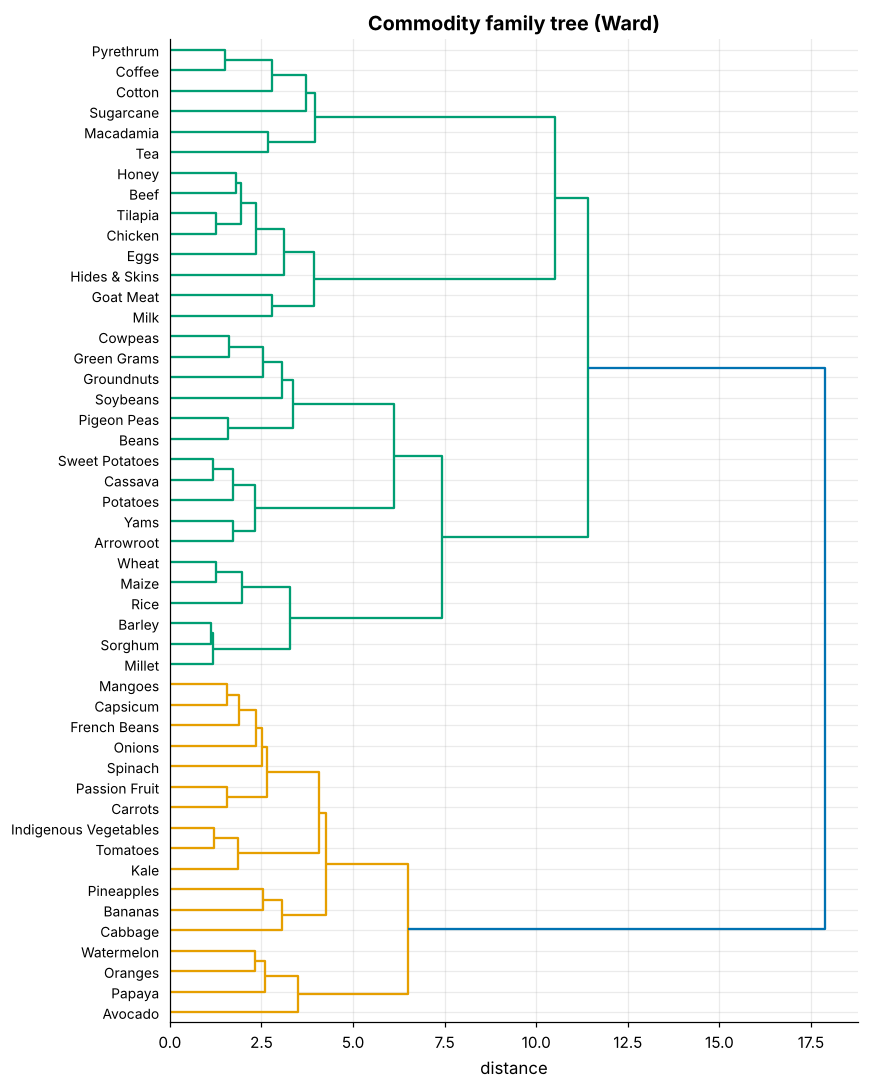

In [5]:
coph = {m: cophenet(linkage(X_p, m), pdist(X_p))[0] for m in ["single", "complete", "average", "ward"]}
print({k: round(v, 3) for k, v in coph.items()})
# Average linkage preserves distances best, but Ward gives compact, balanced groups, which suit policy packages; we use Ward.
Z = linkage(X_p, method="ward")
plt.figure(figsize=(8, 10)); dendrogram(Z, labels=products["product"].values, orientation="right", leaf_font_size=9)
plt.title("Commodity family tree (Ward)"); plt.xlabel("distance"); plt.tight_layout(); plt.show()
chosen_k = 7
group = fcluster(Z, chosen_k, "maxclust")

In [6]:
# ✔ Self-check (run me after you've written your answer)
check('all four linkages evaluated', lambda: set(coph) == {'single', 'complete', 'average', 'ward'})
check('Z has 47 merges', lambda: Z.shape == (47, 4))
check('chosen_k is between 5 and 8', lambda: 5 <= chosen_k <= 8)
check('one group per product', lambda: len(group) == 48 and len(set(group)) == chosen_k)

✅ all four linkages evaluated
✅ Z has 47 merges
✅ chosen_k is between 5 and 8
✅ one group per product


## Milestone 3 · Cross-check with K-Means 🔁

### 🧩 Milestone 3: Do two algorithms agree?
**Difficulty:** ⭐⭐  |  **Time:** ~12 min

Fit `KMeans(chosen_k, n_init=10, random_state=42)` on `X_p` → `km_labels`. Compute `ari_km_ward` and `sil_ward` (the silhouette score of **your Ward grouping** `group` on `X_p`).

Where they disagree, which products are involved? Store `disagree_products`: the **list of product names** whose cluster, after optimally matching Ward groups to K-Means clusters, differs. *(Simplified approach allowed: for each Ward group, find the K-Means cluster most of its members belong to and flag members that fall elsewhere.)*

<details><summary>💡 Hint 1</summary>

`ari_km_ward = adjusted_rand_score(km_labels, group)`; `sil_ward = silhouette_score(X_p, group)`

</details>
<details><summary>💡 Hint 2</summary>

For each Ward group `g`: `maj = pd.Series(km_labels[group == g]).mode()[0]`; products in `g` with `km_labels != maj` are flagged.

</details>
<details><summary>💡 Hint 3</summary>

Use `np.where(group == g)[0]` to get row positions, then `products['product'].iloc[idx]`.

</details>

In [7]:
km_labels = KMeans(chosen_k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_p)
ari_km_ward = adjusted_rand_score(km_labels, group)
sil_ward = silhouette_score(X_p, group)
disagree_products = []
for g in set(group):
    idx = np.where(group == g)[0]
    maj = pd.Series(km_labels[idx]).mode()[0]
    disagree_products += products["product"].iloc[idx[km_labels[idx] != maj]].tolist()
print(round(ari_km_ward, 2), round(sil_ward, 2), disagree_products)

1.0 0.28 []


In [8]:
# ✔ Self-check (run me after you've written your answer)
check('the two methods broadly agree (ARI > 0.6)', lambda: ari_km_ward > 0.6)
check('silhouette is positive', lambda: sil_ward > 0)
check('disagree_products is a list', lambda: isinstance(disagree_products, list))

✅ the two methods broadly agree (ARI > 0.6)
✅ silhouette is positive
✅ disagree_products is a list


## Milestone 4 · Name the groups 🏷️

### 🧩 Milestone 4: Profiles and names
**Difficulty:** ⭐⭐  |  **Time:** ~20 min

Build `prod = products.copy()` with `prod["group"] = group`. Show the **members** of each group, the **profile** (`profile_clusters` over the original `feature_cols`) and a relative heatmap.

Then create `group_names`: one **unique** descriptive name per group id (e.g. *"Storable staple grains"*, *"Perishable fresh produce"*, *"Export cash crops"*, *"Livestock & animal products"*, *"Pulses & legumes"*, *"Roots & tubers"*), **grounded in the profile numbers**, and `prod["group_name"]`.

<details><summary>💡 Hint 1</summary>

`prod.groupby('group')['product'].apply(list)` lists members. Names often become obvious when you read the members!

</details>
<details><summary>💡 Hint 2</summary>

Back them up with numbers: cash crops → highest `export_share`; produce → shortest `shelf_life_days` and highest `price_cv`; livestock products → highest `avg_price_kes_per_kg`.

</details>
<details><summary>💡 Hint 3</summary>

`prod['group_name'] = prod['group'].map(group_names)`

</details>

Group 1 (4): Avocado, Oranges, Watermelon, Papaya
Group 2 (13): Tomatoes, Kale, Cabbage, Onions, Spinach, Capsicum, Carrots, French Beans, Indigenous Vegetables, Bananas, Mangoes, Pineapples, Passion Fruit
Group 3 (6): Maize, Wheat, Rice, Sorghum, Millet, Barley
Group 4 (5): Potatoes, Cassava, Sweet Potatoes, Arrowroot, Yams
Group 5 (6): Beans, Green Grams, Cowpeas, Pigeon Peas, Groundnuts, Soybeans
Group 6 (8): Milk, Eggs, Beef, Goat Meat, Chicken, Honey, Tilapia, Hides & Skins
Group 7 (6): Tea, Coffee, Cotton, Sugarcane, Pyrethrum, Macadamia


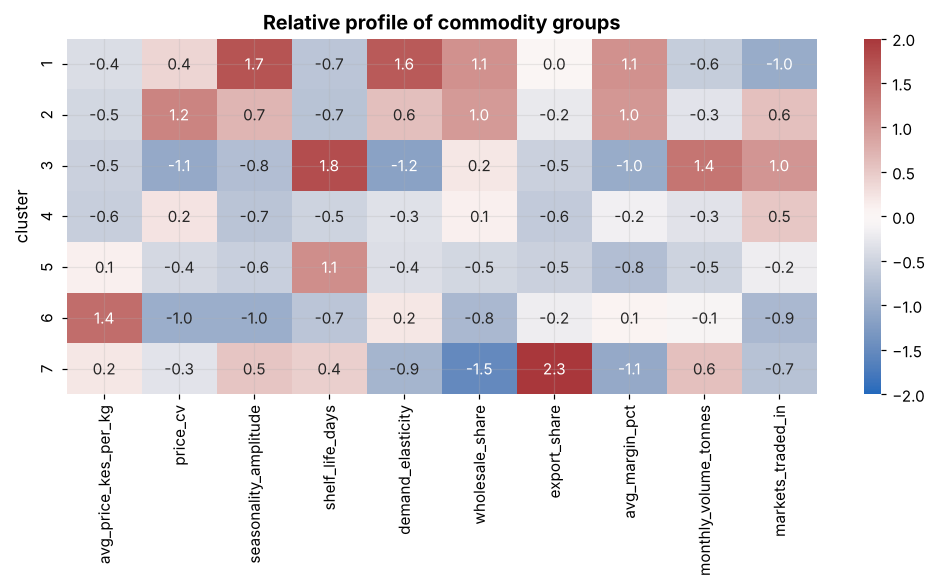

{1: 'Other seasonal fruit', 2: 'Perishable vegetables & tropical fruit', 3: 'Storable staple grains', 4: 'Roots & tubers', 5: 'Pulses & legumes', 6: 'Livestock & animal products', 7: 'Export cash crops'}


In [9]:
prod = products.copy(); prod["group"] = group
for g, members in prod.groupby("group")["product"]:
    print(f"Group {g} ({len(members)}): {', '.join(members)}")
profile = profile_clusters(prod, group, feature_cols)
relative = (profile[feature_cols] - prod[feature_cols].mean()) / prod[feature_cols].std()
plt.figure(figsize=(11, 4.2)); sns.heatmap(relative, annot=True, fmt=".1f", cmap="vlag", center=0, vmin=-2, vmax=2); plt.title("Relative profile of commodity groups"); plt.show()

# Name each group by READING ITS MEMBERS (above) and checking the heatmap agrees. We look for a telltale member in each group:
telltale = {"Maize": "Storable staple grains", "Beans": "Pulses & legumes", "Potatoes": "Roots & tubers",
            "Tomatoes": "Perishable vegetables & tropical fruit", "Avocado": "Other seasonal fruit",
            "Milk": "Livestock & animal products", "Tea": "Export cash crops"}
group_names = {}
for g, members in prod.groupby("group")["product"]:
    hit = next((name for key, name in telltale.items() if key in set(members)), f"Group {g}")
    group_names[g] = hit
# Heatmap sanity check: cash crops should show the highest export share, vegetables/fruit the shortest shelf life and highest volatility.
prod["group_name"] = prod["group"].map(group_names)
print(group_names)

In [10]:
# ✔ Self-check (run me after you've written your answer)
check('each group has a unique name', lambda: set(group_names) == set(group) and len(set(group_names.values())) == chosen_k)
check('every product has a group name', lambda: prod['group_name'].notna().all())
check('Tea and Coffee share a group', lambda: prod.loc[prod['product'] == 'Tea', 'group'].iloc[0] == prod.loc[prod['product'] == 'Coffee', 'group'].iloc[0])
check('Tomatoes and Kale share a group', lambda: prod.loc[prod['product'] == 'Tomatoes', 'group'].iloc[0] == prod.loc[prod['product'] == 'Kale', 'group'].iloc[0])
check('Maize and Tomatoes do NOT share a group', lambda: prod.loc[prod['product'] == 'Maize', 'group'].iloc[0] != prod.loc[prod['product'] == 'Tomatoes', 'group'].iloc[0])

✅ each group has a unique name
✅ every product has a group name
✅ Tea and Coffee share a group
✅ Tomatoes and Kale share a group
✅ Maize and Tomatoes do NOT share a group


## Milestone 5 · A map of commodities 🗺️

### 🧩 Milestone 5: PCA scatter with labels
**Difficulty:** ⭐  |  **Time:** ~10 min

Project `X_p` to 2-D → `Z2`; scatter-plot coloured by `group_name`, **annotate every point with the product name** (small font), and put the variance explained in the axis labels. Store `pc_share` = the total variance explained by the two PCs.

<details><summary>💡 Hint 1</summary>

`pca = PCA(2).fit(X_p); Z2 = pca.transform(X_p); pc_share = pca.explained_variance_ratio_.sum()`

</details>
<details><summary>💡 Hint 2</summary>

`for (x, y), name in zip(Z2, prod['product']): plt.annotate(name, (x, y), fontsize=7, xytext=(3, 3), textcoords='offset points')`

</details>

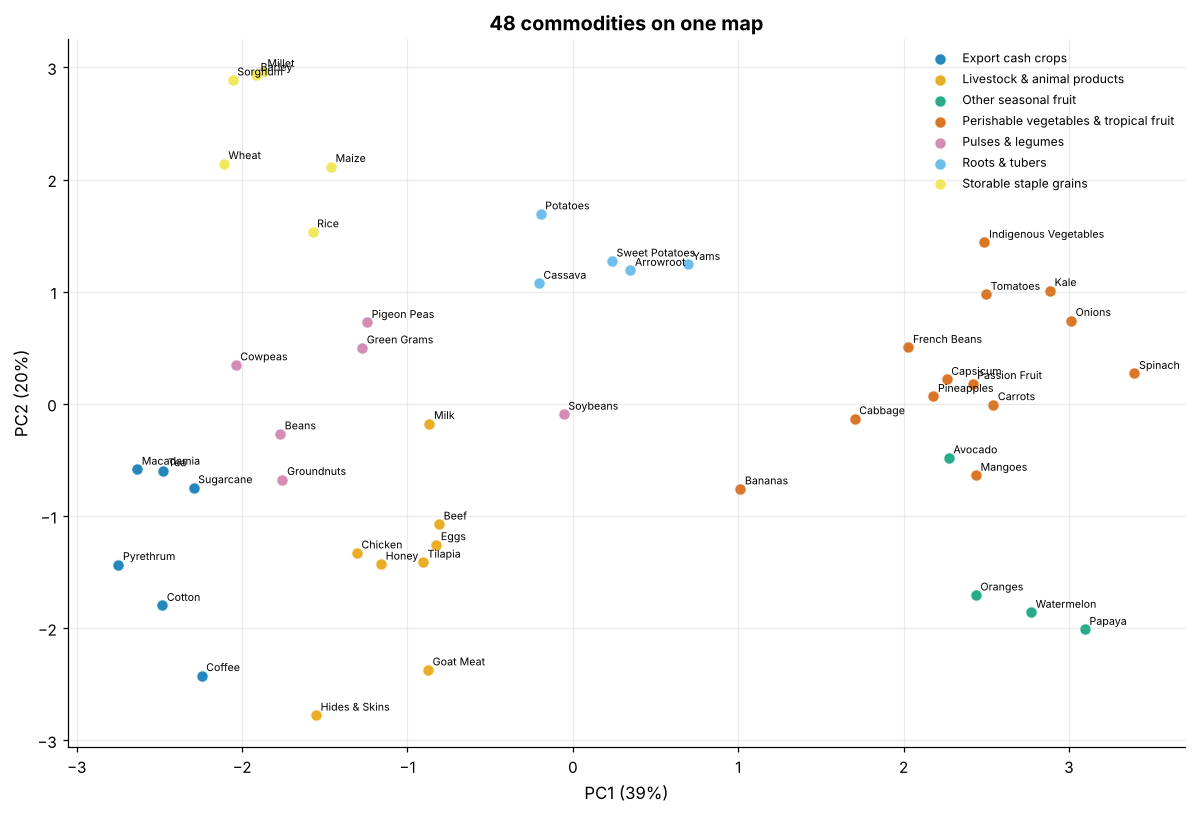

In [11]:
pca = PCA(2).fit(X_p); Z2 = pca.transform(X_p); pc_share = pca.explained_variance_ratio_.sum()
fig, ax = plt.subplots(figsize=(11, 7.5))
for i, name in enumerate(sorted(prod["group_name"].unique())):
    m = (prod["group_name"] == name).values
    ax.scatter(Z2[m, 0], Z2[m, 1], s=60, color=PALETTE[i % len(PALETTE)], label=name, alpha=.85, edgecolor="white")
for (x, y), nm in zip(Z2, prod["product"]):
    ax.annotate(nm, (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})"); ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.set_title("48 commodities on one map"); ax.legend(fontsize=8, loc="best"); plt.tight_layout(); plt.show()

In [12]:
# ✔ Self-check (run me after you've written your answer)
check('Z2 is 48 x 2', lambda: Z2.shape == (48, 2))
check('the two PCs explain between 30% and 90%', lambda: 0.3 < pc_share < 0.9)

✅ Z2 is 48 x 2
✅ the two PCs explain between 30% and 90%


## Milestone 6 · Policy metrics 📊

### 🧩 Milestone 6: Which group needs which policy?
**Difficulty:** ⭐⭐  |  **Time:** ~12 min

Using `prod`, compute **group-level** means and identify:

- `most_volatile_group`: group **name** with the highest mean `price_cv` (→ price-stabilisation / information)
- `most_perishable_group`: lowest mean `shelf_life_days` (→ cold chain)
- `most_exported_group`: highest mean `export_share` (→ export support)
- `highest_margin_group`: highest mean `avg_margin_pct`
- `volume_share`: a Series: each group's share (0–1) of total `monthly_volume_tonnes`

<details><summary>💡 Hint 1</summary>

`g = prod.groupby('group_name')[feature_cols].mean()`; then `g['price_cv'].idxmax()`.

</details>
<details><summary>💡 Hint 2</summary>

`prod.groupby('group_name')['monthly_volume_tonnes'].sum() / prod['monthly_volume_tonnes'].sum()`

</details>

In [13]:
g = prod.groupby("group_name")[feature_cols].mean()
most_volatile_group, most_perishable_group = g["price_cv"].idxmax(), g["shelf_life_days"].idxmin()
most_exported_group, highest_margin_group = g["export_share"].idxmax(), g["avg_margin_pct"].idxmax()
volume_share = prod.groupby("group_name")["monthly_volume_tonnes"].sum() / prod["monthly_volume_tonnes"].sum()
display(g[["price_cv", "shelf_life_days", "export_share", "avg_margin_pct"]].round(2))
print(most_volatile_group, "|", most_perishable_group, "|", most_exported_group, "|", highest_margin_group)

,price_cv,shelf_life_days,export_share,avg_margin_pct
group_name,,,,
Export cash crops,0.22,173.33,0.72,13.45
Livestock & animal products,0.12,13.62,0.11,22.81
Other seasonal fruit,0.32,11.75,0.16,31.20
Perishable vegetables & tropical fruit,0.44,8.31,0.10,30.60
Pulses & legumes,0.20,265.17,0.03,15.82
Roots & tubers,0.30,37.20,0.01,20.88
Storable staple grains,0.11,362.17,0.03,13.70


Perishable vegetables & tropical fruit | Perishable vegetables & tropical fruit | Export cash crops | Other seasonal fruit


In [14]:
# ✔ Self-check (run me after you've written your answer)
check('volume shares sum to 1', lambda: abs(volume_share.sum() - 1) < 1e-9)
check('the export group has the highest export share', lambda: g.loc[most_exported_group, 'export_share'] == g['export_share'].max())
check('most perishable group has the shortest shelf life (< 30 days)', lambda: g.loc[most_perishable_group, 'shelf_life_days'] < 30)
check('perishable and volatile are the same kind of group (produce)', lambda: g.loc[most_volatile_group, 'shelf_life_days'] < 30)

✅ volume shares sum to 1
✅ the export group has the highest export share
✅ most perishable group has the shortest shelf life (< 30 days)
✅ perishable and volatile are the same kind of group (produce)


## Milestone 7 · Find the misfits 🔎

A commodity that sits awkwardly in its group deserves special treatment. The **per-sample silhouette** measures this: low or negative = a poor fit.

### 🧩 Milestone 7: Which commodities don't belong?
**Difficulty:** ⭐⭐  |  **Time:** ~10 min

1. `sil_samples = silhouette_samples(X_p, group)`; add it to `prod["fit"]`.
2. `n_negative` = number of products with **negative** fit.
3. `worst_fit` = a DataFrame of the **5 worst-fitting** products (columns: `product`, `group_name`, `fit`).
4. `best_fit_product` = the product with the **highest** fit.

*Interpretation:* why might the worst fits be borderline? (Which neighbouring group are they close to?)

<details><summary>💡 Hint 1</summary>

`prod['fit'] = silhouette_samples(X_p, group)`

</details>
<details><summary>💡 Hint 2</summary>

`prod.nsmallest(5, 'fit')[['product', 'group_name', 'fit']]`

</details>
<details><summary>💡 Hint 3</summary>

Borderline items are usually halfway between two families, e.g. a fruit with produce-like perishability but export orientation.

</details>

In [15]:
prod["fit"] = silhouette_samples(X_p, group)
n_negative = int((prod["fit"] < 0).sum())
worst_fit = prod.nsmallest(5, "fit")[["product", "group_name", "fit"]]
best_fit_product = prod.loc[prod["fit"].idxmax(), "product"]
display(worst_fit.round(2)); print(n_negative, best_fit_product)

,product,group_name,fit
34,Tea,Export cash crops,-0.02
23,Avocado,Other seasonal fruit,-0.01
21,Bananas,Perishable vegetables & tropical fruit,0.02
41,Eggs,Livestock & animal products,0.05
14,Cabbage,Perishable vegetables & tropical fruit,0.06


2 Sweet Potatoes


In [16]:
# ✔ Self-check (run me after you've written your answer)
check('silhouette_samples has 48 values', lambda: len(prod['fit']) == 48)
check('worst_fit has 5 rows', lambda: len(worst_fit) == 5)
check('worst fit is below the average fit', lambda: worst_fit['fit'].max() < prod['fit'].mean())
check('best_fit_product is a real product', lambda: best_fit_product in set(products['product']))

✅ silhouette_samples has 48 values
✅ worst_fit has 5 rows
✅ worst fit is below the average fit
✅ best_fit_product is a real product


## Milestone 8 · The memo ✍️

### ✍️ Memo to the Director of Market Policy
*(Example answer. Yours will differ in wording and possibly in numbers.)*

**To:** Grace Njoroge  **From:** Market Policy Analytics

**Recommendation.** Instead of 48 separate policies, adopt **seven commodity policy packages**.

| Package | Members | What they share | Policy lever |
|---|---|---|---|
| Storable staple grains | Maize, Wheat, Rice, Sorghum, Millet, Barley | Shelf life ~1 year, low price volatility (CV ≈ 0.12), high wholesale share | Strategic reserves, warehouse receipts |
| Pulses & legumes | Beans, Green grams, Cowpeas, Pigeon peas, Groundnuts, Soybeans | Storable, mid-high price per kg, moderate seasonality | Aggregation and quality grading |
| Roots & tubers | Potatoes, Cassava, Sweet potatoes, Arrowroot, Yams | Medium shelf life (~40 days), moderate volatility | Curing/storage and processing |
| Perishable vegetables & tropical fruit | Tomatoes, Kale, Cabbage, Onions, Spinach, Capsicum, Bananas, Mangoes... | Shelf life under ~10 days, price volatility ≈ 0.4, strong seasonality | **Cold chain, market-price SMS, collection centres** |
| Other fruits | Avocado, Oranges, Watermelon, Papaya | Perishable and seasonal, some export interest | Packhouses, export linkage |
| Livestock & animal products | Milk, Eggs, Beef, Goat meat, Chicken, Honey, Tilapia, Hides & skins | Highest price per kg, short shelf life, low volatility | Cooling plants, quality standards |
| Export cash crops | Tea, Coffee, Cotton, Sugarcane, Pyrethrum, Macadamia | Export share ~80%, long shelf life | Export promotion, price-risk tools |

*(Your groups and numbers should come from your own tables. Group count and membership may differ.)*

**Commodities needing special treatment.** The lowest-silhouette items (in our run: **Tea, Avocado, Bananas, Eggs, Cabbage**; see `worst_fit`) sit on the boundary between two families. For example, Avocado and Bananas are as perishable as vegetables but more export-oriented, and Tea is a cash crop that behaves partly like a storable staple. They may need hybrid packages or case-by-case treatment.

**Confidence.** Ward hierarchical clustering and K-Means produced essentially the *same* seven groups (ARI ≈ 1.0), which is strong evidence the structure is real. The overall silhouette is modest (≈ 0.28): groups are genuine but touch at their edges, especially the fruit/vegetable boundary. Groupings follow *market behaviour*, not botany, which is what a policy package needs.

**Next step.** Pilot the **perishable vegetables & fruit package** first: highest volatility and shortest shelf life, so the greatest potential loss reduction.

## 🚀 Stretch challenges
1. **Robustness.** Re-run with the **log transform removed**. How many products change group (ARI)?
2. **Add a feature.** Invent one (e.g. `price_per_shelf_day = avg_price / shelf_life`). Does the tree change?
3. **Truth check.** `products_truth.csv` has the 7 true categories. Which commodities did your tree put *outside* their category, and does the data justify it?
4. **Link to farmers.** Map `primary_crop` in `farmers.csv` to your groups. What share of farmers grow perishables? *(You'll do this in the Capstone!)*

### 🏁 Self-review checklist
- [ ] I log-transformed **only** columns that were skewed *and* positive
- [ ] My group names can be defended with numbers from the profile
- [ ] I read the member list of every group and sanity-checked it
- [ ] I flagged misfits rather than hiding them
- [ ] My memo ties each group to **one** policy lever